## 1. 인트로

### 1-1. RNN의 한계와 어텐션의 등장

> **핵심** Seq2Seq는 컨텍스트 벡터 하나에 모든 정보를 담아서 병목이 생김 → Attention은 출력 단어마다 입력 문장 전체를 다시 보고 필요한 부분에 집중함

**Seq2Seq 복습**
입력 시퀀스를 받아 다른 시퀀스로 바꾸는 모델. 입력과 출력의 길이가 달라도 되고(영어 3단어 → 한국어 5단어) 번역, 요약, 음성 인식 등에 쓰임. 인코더가 "I, study, math, hard"를 LSTM으로 한 단어씩 읽고 문장 전체를 하나의 **Context Vector**로 압축하면, 디코더가 그걸 받아 `<sos>` → "나는" → "수학을" … 순으로 한 단어씩 만들고 `<eos>`에서 멈춤. 즉 디코더가 참고할 수 있는 건 Context Vector **하나뿐**임.

**Attention의 등장배경: Seq2Seq의 병목 현상**
- Context Vector 크기가 고정이라 5단어든 50단어든 같은 크기에 담아야 함 → 문장이 길수록 정보 손실
- "나는"을 만들 때도 "수학을"을 만들 때도 똑같은 요약본만 봄 → 단어마다 필요한 정보를 다르게 반영X
- Context Vector는 인코더의 마지막 hidden state라 마지막 단어는 진하게 남고 앞쪽 단어는 희미해짐

그래서 등장한 게 **Attention**. 디코더가 단어를 만들 때마다 입력 문장 전체를 다시 보고, 현재 단어와 관련 있는 부분에 집중해서 출력 단어마다 **새로운 Context Vector**를 만듦.

**Attention의 정의**
현재 시점에서 가장 중요한 부분에 더 높은 가중치를 주는 기술. 출력 단어를 만들 때 입력 문장 속 어떤 단어에 더 집중할지 정도를 결정함.

"I am a student" → "je suis ___" 다음 단어를 예측하는 상황으로 보면
- 인코더는 마지막 hidden state 하나가 아니라 **4개 hidden state를 모두** 남겨 둠
- 디코더의 현재 상태를 인코더의 각 hidden state와 비교해 관련도 점수를 냄
- Softmax로 합이 1인 비율(어텐션 가중치)로 바꾸면 'student'가 가장 높게 나옴
- 이 비율대로 섞어 지금 필요한 정보만 모은 Context Vector를 만들고 → 디코더 상태와 합쳐 Dense + Softmax → *étudiant* 출력

기존 Seq2Seq는 순서대로 전달받은 결과만 쓰지만 Attention은 **모든 위치를 직접 비교**함. student의 점수를 구하려고 I, am, a의 점수를 먼저 구할 필요가 없으니 각 점수를 **동시에 계산** 가능 → 병렬화 가능성!
BUT 이 구조에선 인코더와 디코더가 여전히 LSTM이라 모델 전체 병렬화는 안 됨 → attention은 아직 **RNN의 보조 역할**. LSTM을 걷어내고 어텐션만 남긴 게 다음에 나오는 **Transformer**임.

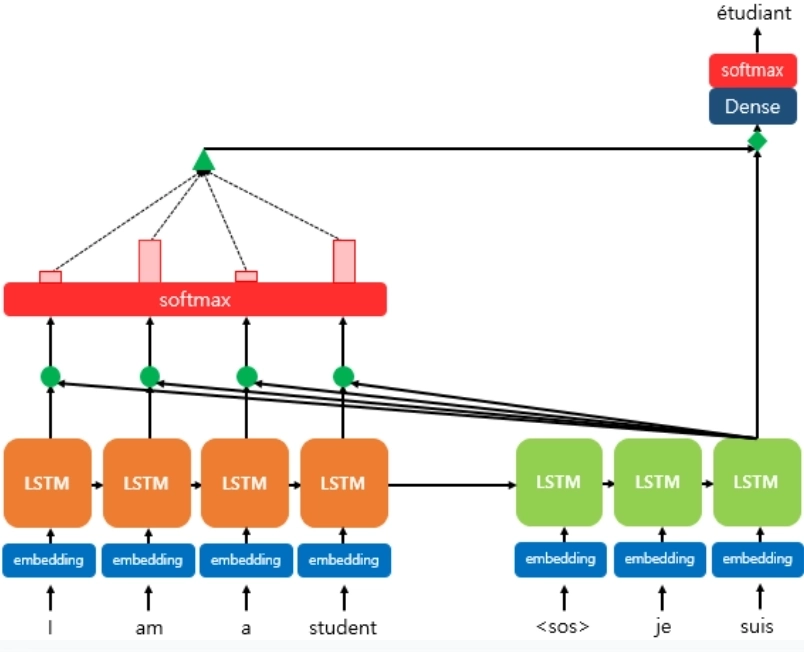

**Attention의 과정**
1. 입력 단어를 숫자 벡터로 변환
2. 단어별 중요도 계산: 현재 작업과 각 단어의 **관련도 점수** → **Softmax**로 합이 1인 비율(Attention Weight)로 변환. EX. student 관련도 3.8점 → 가중치 80% = "student에 80% 집중하겠다"
3. 가중치만큼 각 단어의 hidden state를 섞어 Context Vector 생성 → 비율이 높은 단어 위주로 반영
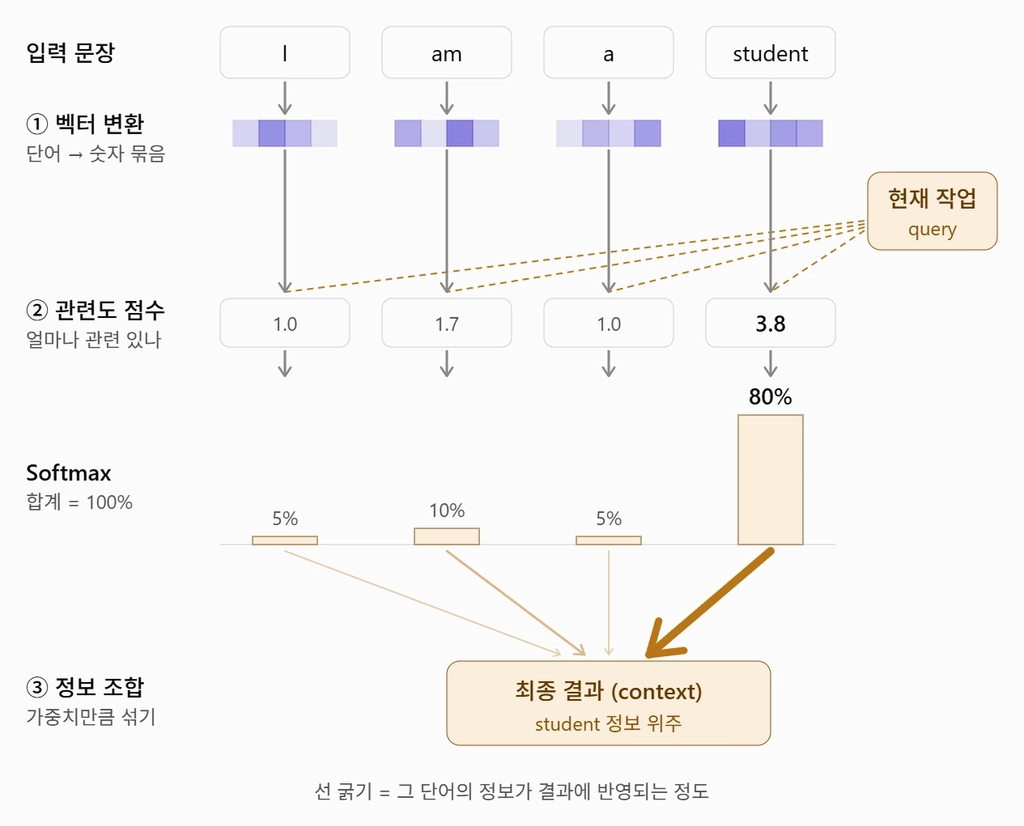

**Attention의 장점**
- **시간 유연성 (vs RNN)**: RNN은 한 단계씩 전달해서 멀수록 흐려지지만, Attention은 모든 단어를 직접 비교해 거리와 상관없이 관계 파악
- **공간 유연성 (vs CNN)**: CNN은 고정 크기 필터로 주변만 봐서 멀리 있는 걸 연결하려면 층을 많이 쌓아야 하지만, Attention은 한 번에 전역적인 관계를 학습
- **병렬화 (vs RNN)**: 단어 쌍마다 관련도 계산이 서로 독립적이라 동시에 계산 가능 → RNN을 완전히 뺀 Transformer에서 제대로 발휘됨

| 모델 | 한계 |
| --- | --- |
| RNN | 장기 의존성 문제 + 병렬화 불가 |
| LSTM | 장기 의존성은 완화했지만 순차 구조는 그대로 |
| Seq2Seq + Attention | 병목 현상은 해결했지만 여전히 RNN 위에서 작동하는 보조 역할 |

---

### 1-2. Attention is All You Need

> **핵심** RNN과 CNN을 완전히 빼고 Attention만으로 만든 Transformer를 제안한 논문 → 오늘날 LLM의 기반

2017년 NIPS에서 Google Brain·Google Research 연구진 8명이 발표한 논문. 제목 그대로 "Attention만 있으면 된다"는 주장임.

- **배경**: RNN, LSTM, GRU가 시퀀스 작업의 표준이었지만 n번째 단어를 계산하려면 n-1번째 결과가 먼저 필요한 순차 구조라 한 문장 안에서 병렬 처리X. Attention은 RNN의 보조 역할에 그침
- **제안**: RNN과 CNN을 완전히 제거하고 **Self-Attention**으로 입력과 출력의 관계를 계산하는 Transformer
- **가장 중요한 발견**: *"Recurrence와 Convolution은 필수가 아니다"* → Attention만으로 더 좋은 성능 + 순차 구조를 없애서 병렬화로 빠른 학습 가능
- **파급효과**: 디코더를 쌓은 GPT, 인코더를 쌓은 BERT가 나오며 LLM의 기반이 됨. 번역·요약·질의응답 등 NLP의 표준 구조가 되었고, 이미지·음성 등으로도 확장 (논문 결론에서도 이미지·오디오·비디오 확장을 향후 계획으로 언급)

**Transformer란?**
단어를 순서대로 처리하지 않고 **Attention만으로 문장 전체의 의미와 구조를 파악해 한 번에 처리**하는 인코더-디코더 모델. 왼쪽 인코더가 입력 문장을 이해하고 오른쪽 디코더가 출력 문장을 만들며, 층 하나를 N개 쌓아 구성함. 기존 모델과의 차이는 결국 **인코더·디코더 내부를 무엇으로 채웠는가**임.

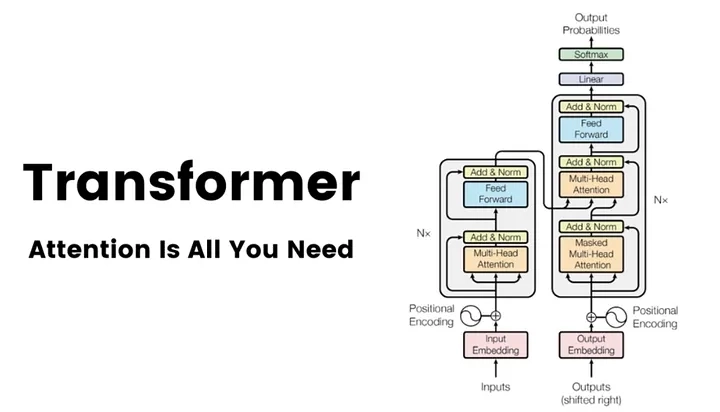

| 구분 | Seq2Seq + Attention | Transformer |
| --- | --- | --- |
| 인코더, 디코더 내부 | LSTM (순차 처리) | Self-Attention |
| 어텐션의 역할 | RNN을 돕는 보조 역할 | 모델 그 자체 |
| 어텐션 사용 위치 | 디코더 → 인코더 1곳 | 인코더 내부, 디코더 내부, 인코더-디코더 사이 3곳 |
| 단어 순서 정보 | RNN이 순서대로 읽으며 반영 | Positional Encoding으로 따로 추가 |
| 병렬 처리 | 불가 | 가능 |

**핵심 기술 3가지**
- **Self-Attention**: 문장 안 단어들이 서로를 참고해 어떤 관계인지 한 번에 문맥 파악
- **Multi-Head Attention**: Attention을 여러 갈래로 나눠 다양한 관점에서 관계 파악
- **Positional Encoding**: 단어 위치를 벡터로 만들어 더해서 사라진 순서 정보를 보완

---

## 2. Self-Attention

### 2-1. Query, Key, Value

> **핵심** Attention = Query를 Key들과 비교해 관련도를 구하고, 그 비율만큼 Value를 섞어 결과를 만드는 계산

**RNN·LSTM 한계 복습**
RNN은 이전 단계 정보를 다음 단계로 넘기며 기억하는 신경망이고, 모든 시점에서 같은 가중치를 쓰는 **가중치 공유** 덕분에 파라미터가 효율적이고 일반화가 가능함. BUT 문장이 길어지면 BPTT에서 가중치가 계속 곱해지면서 값이 발산하거나(Exploding) 0이 되어(Vanishing) 초반 정보가 후반에 반영되지 않는 **장기 의존성 문제**가 생김. MT 때 했던 이름쌓기 "00옆에 00옆에 00옆에…"를 떠올리면 됨..

LSTM은 "중요한 건 오래 기억하고 필요 없는 건 잊자"는 아이디어로, 가중치 곱 없이 직선으로 흐르는 **Cell state**(중요한 걸 적어 두는 메모장)와 Input·Forget·Output 3개 게이트로 정보를 관리함. 오래된 정보도 기억하고 gradient도 유지되지만, 게이트 3개라 계산이 복잡하고 **긴 문장에선 여전히 Vanishing gradient**가 생김. 초반 데이터일수록 forget gate를 통과해야 하는 횟수가 많기 때문 (오징어게임 징검다리 건너기!)

결국 LSTM은 기억 전달 방식은 개선했지만 순서대로 처리하는 구조는 그대로임. Transformer는 구조 자체를 바꿔 **모든 단어를 서로 직접 비교**하고, 이때 쓰는 재료가 Q, K, V임.

**Q, K, V 개념** (도서관에서 책 찾기로 보면)
- **Query**: 현재 단어가 "지금 나한테 필요한 정보가 뭐지?"라고 묻는 벡터 → "'학생'에 대해 알고 싶어"
- **Key**: 각 단어가 "나는 이런 정보를 가지고 있어"라고 보여주는 이름표. Query와 비교해 관련도를 정함 → '학교 생활', '교육학 개론', '요리 레시피', '주식 투자' 제목표를 '학생'과 비교해 60%, 35%, 3%, 2%
- **Value**: 각 단어가 실제로 전달하는 정보. 관련도 비율만큼 섞어 최종 결과를 만듦 → 학교 생활 60% + 교육학 개론 35% + 요리 3% + 주식 2% = 최종 답변

Key와 Value는 한 단어에서 같이 만들어진 한 쌍. Key는 "찾을 때 쓰는 기준", Value는 "찾았을 때 가져오는 내용"임. 굳이 나누는 이유는 같은 단어라도 **관련 있는지 판단할 때 필요한 정보**와 **실제로 전달해야 할 정보**가 다를 수 있기 때문!
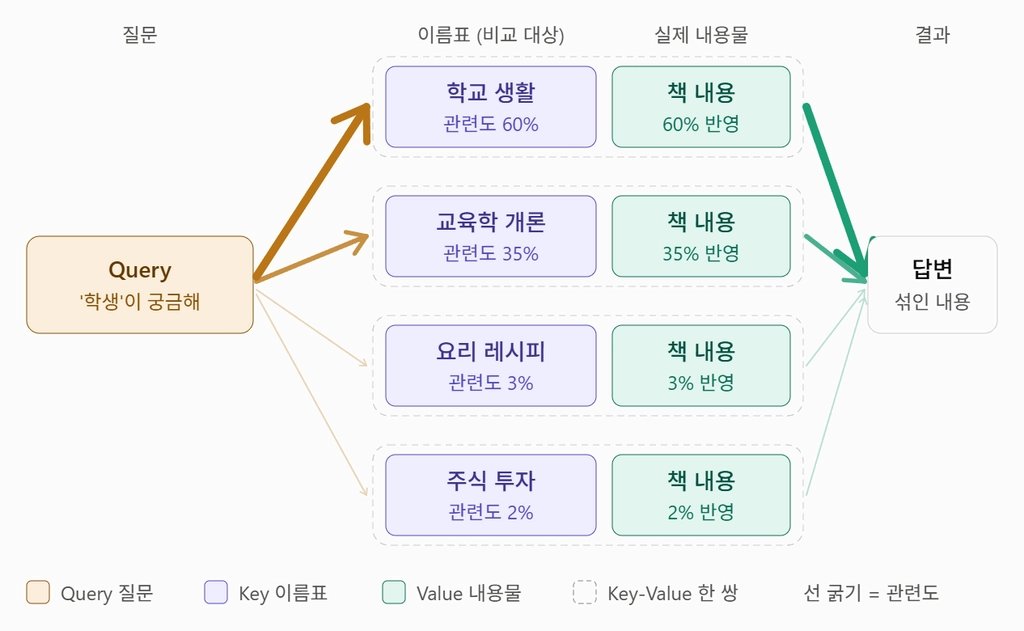
---

### 2-2. 기존 Cross-Attention vs Self-Attention

> **핵심** Cross는 "남에게 묻기"(디코더 → 인코더), Self는 "나에게 묻기"(문장 내부끼리)

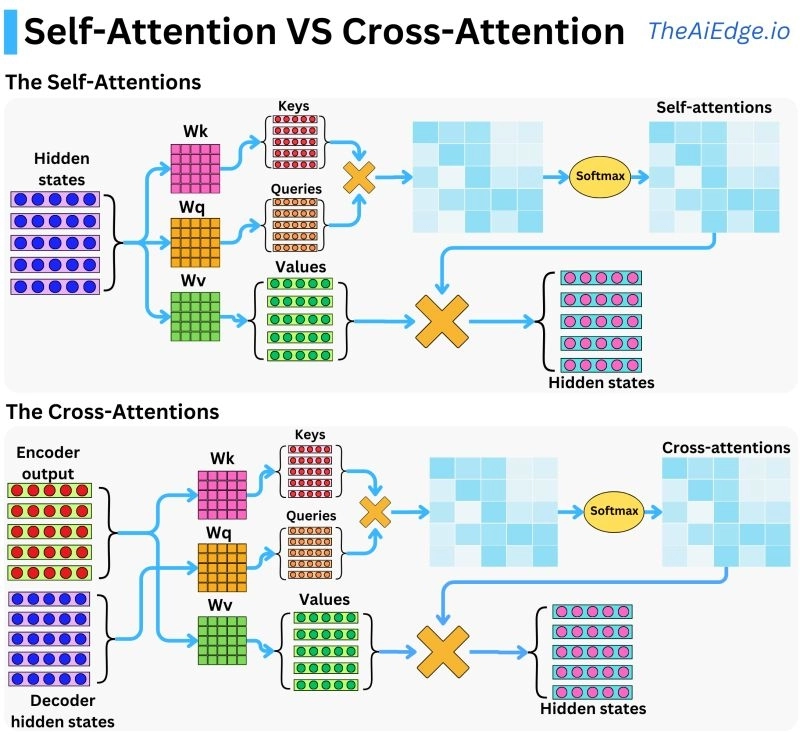

**공통 흐름**
입력을 학습된 변환 Wq, Wk, Wv에 통과시켜 Q, K, V 생성 → Q × K로 모든 단어 쌍의 관련도 표 → Softmax로 각 줄 합을 1로 → 비율 × V = 새로운 hidden states
차이는 Q, K, V를 **어디서 만드냐**임.

**Cross-Attention (Seq2Seq의 기존 Attention)**
Query와 Key-Value가 **서로 다른 시퀀스**에서 나옴 → 디코더가 인코더에게 "지금 어디를 봐야 하지?" 묻는 구조
EX. "The cat is sleeping" → "고양이가 ___"
1. 디코더가 지금까지 만든 "고양이가"로 현재 상태를 Query로 만듦
2. 인코더가 The, cat, is, sleeping에 대해 만든 벡터를 Key, Value로 씀
3. Query와 각 Key를 내적(Q · Kᵢ)해 관련도 계산 → Softmax → The 2%, cat 13%, is 10%, **sleeping 75%**
4. 비율만큼 Value를 섞어 Context Vector → 디코더 정보와 합쳐 "자고" 출력

오픈북 시험처럼 답안을 쓰면서 교과서 어디를 볼지 계속 정하는 과정임. BUT 인코더·디코더가 RNN 위에서 돌아서 원문 내부 관계는 RNN이 간접적으로 파악하고 병렬 처리도 불가함.

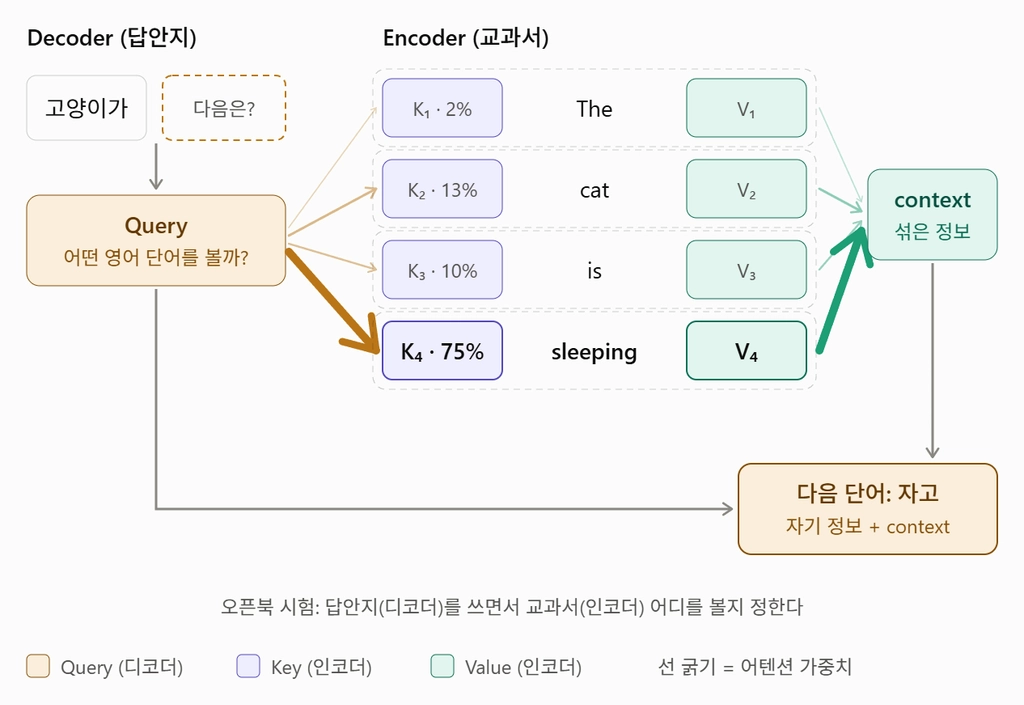

**Self-Attention**
Query와 Key-Value가 **같은 시퀀스**에서 나옴 → 문장이 스스로에게 "우리끼리 누가 누구와 관련 있지?" 묻는 구조. RNN 없이도 문장 내부 관계를 직접 파악함
EX. "가을 은행 냄새 지독해"에서 '은행'의 의미
1. 각 단어를 벡터로 바꾸고 같은 벡터에서 Q, K, V를 만듦
2. '은행'의 Query와 모든 단어의 Key를 비교해 점수 계산 (가로줄 = 질문하는 단어, 세로줄 = 참고 대상)
3. Softmax → 가을 30%, 은행 20%, **냄새 45%**, 지독해 5%
4. 비율만큼 Value를 섞으면 '은행'이 "돈? 열매?"에서 **"가을에 냄새 나는 열매"**라는 의미를 담은 새 벡터가 됨

→ 모든 단어가 이 과정을 **동시에** 거쳐 각자 문맥이 반영된 새 벡터를 얻음 = 병렬 처리 가능!

| 구분 | Cross-Attention | Self-Attention |
| --- | --- | --- |
| 한 줄 요약 | 번역 중인 문장이 원문을 참고 | 문장이 스스로 내부 관계를 파악 |
| Q, K, V 출처 | Q는 디코더, K·V는 인코더 | 같은 문장에서 Q, K, V 모두 생성 |
| 주요 목적 | 고정 Context Vector의 병목 해결 | 문맥이 반영된 단어 표현 생성 |
| 결과 벡터 | Context Vector | 문맥이 반영된 새 표현 |
| 기반 / 병렬처리 | RNN 기반이라 불가 | Transformer라 가능 |

**Transformer는 둘 다 씀**
- 인코더: Self-Attention → 원문 단어끼리 관계 파악
- 디코더: Self-Attention → 번역 중인 문장끼리 관계 파악 (단 아직 안 만든 뒤 단어는 못 보게 눈가리개)
- 인코더-디코더 사이: Cross-Attention → 번역하면서 원문 참고

즉 Seq2Seq에서 RNN이 하던 **문장 내부 이해**는 Self-Attention이, Attention이 하던 **원문 참고**는 Cross-Attention이 그대로 맡는 것임.

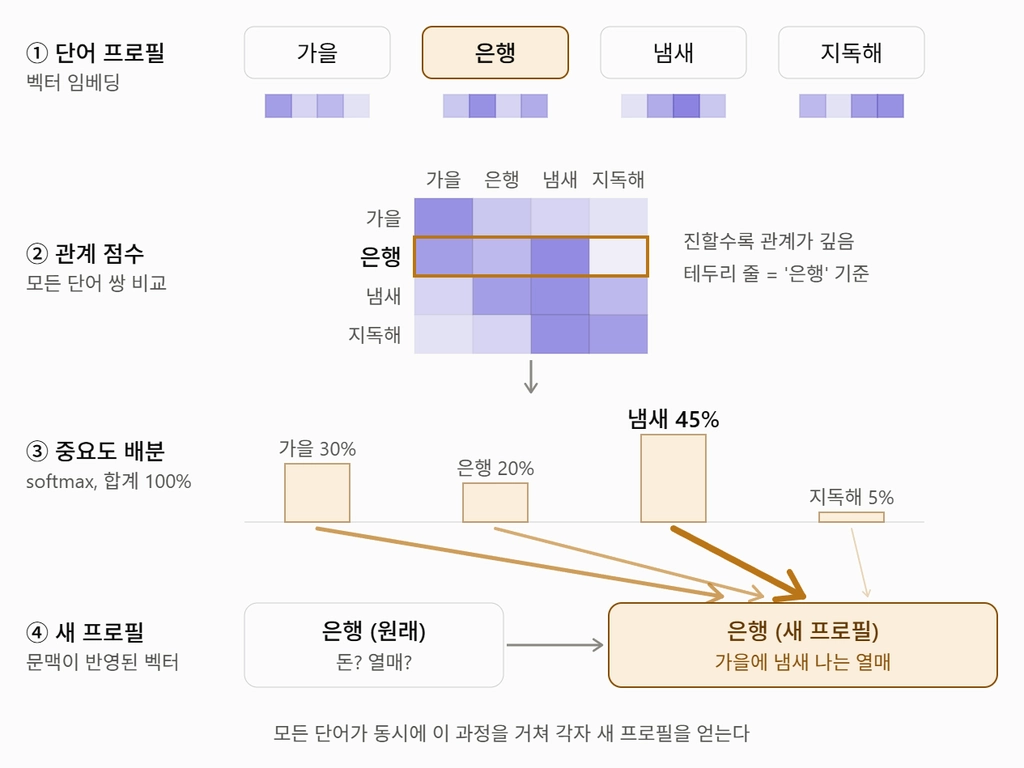

---

### 2-3. Scaled Dot-Product Attention

> **핵심** Q와 K를 내적해 점수를 내고, √dₖ로 나눠 극단적인 값을 막은 뒤 Softmax → V를 섞는 게 Transformer의 Attention 공식

**Dot-Product Attention**
Attention Score를 구하는 가장 기본적인 방법으로 Query와 Key를 **내적**함. 내적은 같은 위치 성분끼리 곱해 다 더한 값이고, 방향이 비슷할수록 커져서 "얼마나 닮았나"를 숫자로 보여줌.

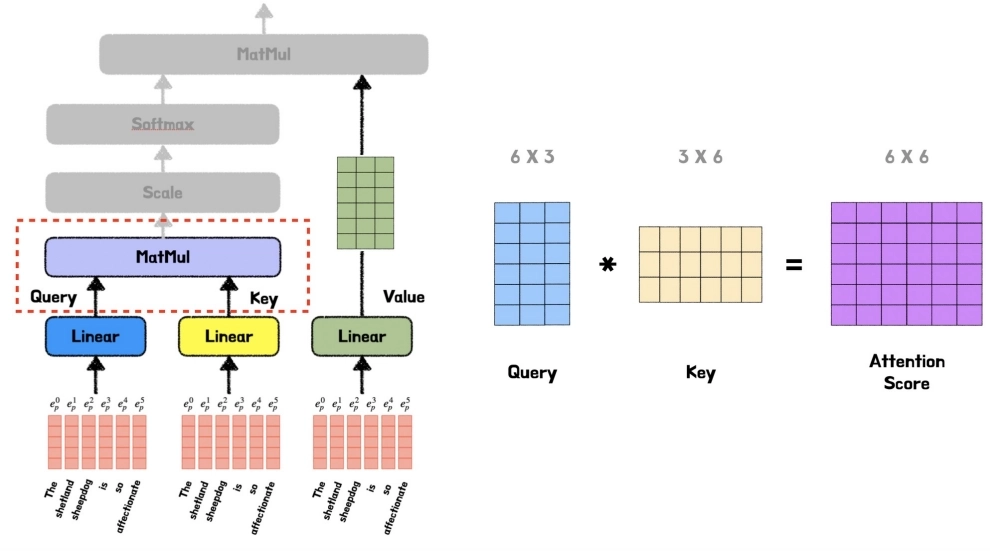



**행렬로 한 번에 계산하기**
- Attention에서 행렬의 한 행 = 한 단어의 벡터 → Q (6×3)는 단어 6개가 각각 3차원 벡터를 가진 것
- 행렬 곱은 앞 행렬의 열 수와 뒤 행렬의 행 수가 같아야 해서 K (6×3)를 **전치**해 Kᵀ (3×6)로 눕힘
- QKᵀ의 i행 j열 = i번째 단어 Query와 j번째 단어 Key의 내적 = 두 단어의 관련도 점수 (EX. shetland 행 × sheepdog 열 = (shetland, sheepdog) 칸)
- 행렬 곱 한 번으로 6×6 = **36개 내적을 동시에** 계산 → 병렬 처리가 실제로 구현되는 지점!

**과정**
1. Q (6×3) × Kᵀ (3×6) → 6×6 관련도 점수표 (가로줄 = 질문하는 단어, 세로줄 = 참고 대상)
2. 각 가로줄에 Softmax → "이 단어는 다른 단어를 몇 %씩 참고하나" = Attention Weight
3. Attention Weight (6×6) × V → 다른 단어 정보를 비율만큼 섞은 새 벡터 6개

**문제점: Attention Score의 극단화**
벡터 차원이 커질수록 내적 값이 너무 커질 수 있음 → Softmax에 들어가면 특정 단어에 확률이 확 몰림 → 기울기가 0에 가까워져 학습이 잘 안 되는 Vanishing Gradient 발생

**Scaled Dot-Product Attention**
논문 저자들이 제안한 Transformer의 Attention 공식 그 자체. 내적과 Softmax 사이에 **스케일링 단계 하나만 추가**함.
1. Query와 모든 Key 내적 → Attention Score
2. **√dₖ로 나눔** → 분산이 1 근처로 돌아와서 차원 크기와 상관없이 점수가 안정적인 범위에 머묾
3. Softmax → Attention Weight
4. Attention Weight × Value → 최종 결과

$$
Attention(Q,K,V)=softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

| | the | shetland | sheepdog | is | so | affectionate |
| --- | --- | --- | --- | --- | --- | --- |
| 스케일링 전 | 0% | 10.7% | 82.2% | 0% | 0% | 7.1% |
| 스케일링 후 | 0% | 19.9% | 64.5% | 0% | 0% | 15.7% |

→ 스케일링 전엔 sheepdog 하나에 82%가 몰리지만, 후에는 shetland, affectionate에도 나눠져서 주변 정보를 고르게 반영함

**결과로 얻는 벡터**
- Cross-Attention: 현재 만드는 단어에 필요한 원문 정보를 모은 **Context Vector**
- Self-Attention: 문장 내 다른 단어와의 관계가 반영되어 **의미가 업데이트된 단어 벡터**

---

## 3. Multi-Head Attention

### 3-1. 왜 Multi-Head Attention을 쓸까?

> **핵심** 헤드 하나는 집중력 100%를 혼자 나눠 써야 해서 정보가 흐려짐 → 헤드를 여러 개 두면 각자 100%를 써서 여러 관계를 또렷하게 잡음

**헤드(Head)란?**
Attention 계산을 **한 번 하는 독립된 단위**. 자기만의 가중치 행렬 세트로 Q·K·V를 만들어 Attention을 한 번 계산하고 결과 벡터 하나를 냄. 헤드마다 가중치 행렬 숫자가 달라서 같은 문장을 봐도 집중하는 단어가 달라짐!

**Single-Head Attention**
가중치 세트 하나로 512차원 벡터를 그대로 한 번 Attention함 → 단어마다 가중치 분포가 딱 하나 나옴.
한계는 **집중력 100%를 혼자 나눠 써야 한다**는 것. Softmax 가중치 합은 항상 1인데, 한 단어를 이해하려면 여러 종류의 관계가 동시에 필요한 경우가 많음. 그러면 100%를 골고루 나눌 수밖에 없고 결과는 여러 정보가 섞여 **흐릿해진 벡터 하나**가 됨.
EX. "Tom gave Mary a book yesterday"에서 'gave'의 가중치가 Tom 0.25, Mary 0.25, a 0.02, book 0.25, yesterday 0.23 → 다 비슷해서 준 사람이 Tom인지 Mary인지 흐려짐

**Multi-Head Attention**
Attention을 작게 쪼개서 여러 번 동시에 하는 방식. 같은 예시에서 헤드 1은 Tom(Who?), 헤드 2는 Mary(To whom?), 헤드 3은 book(What?), 헤드 4는 yesterday(When?)에 각각 0.90씩 집중함. 헤드마다 질문 하나에 집중하고 결과를 **나란히 이어 붙이니까** 정보가 섞이지 않고 또렷하게 남음.

비유하면
- Single-Head = 기자 1명이 혼자 모든 질문을 취재해 기사 한 편 → 다 담지만 얕음
- Multi-Head = 기자 8명이 각자 한 분야만 깊게 취재 + 편집장이 8편을 엮어 한 기사로

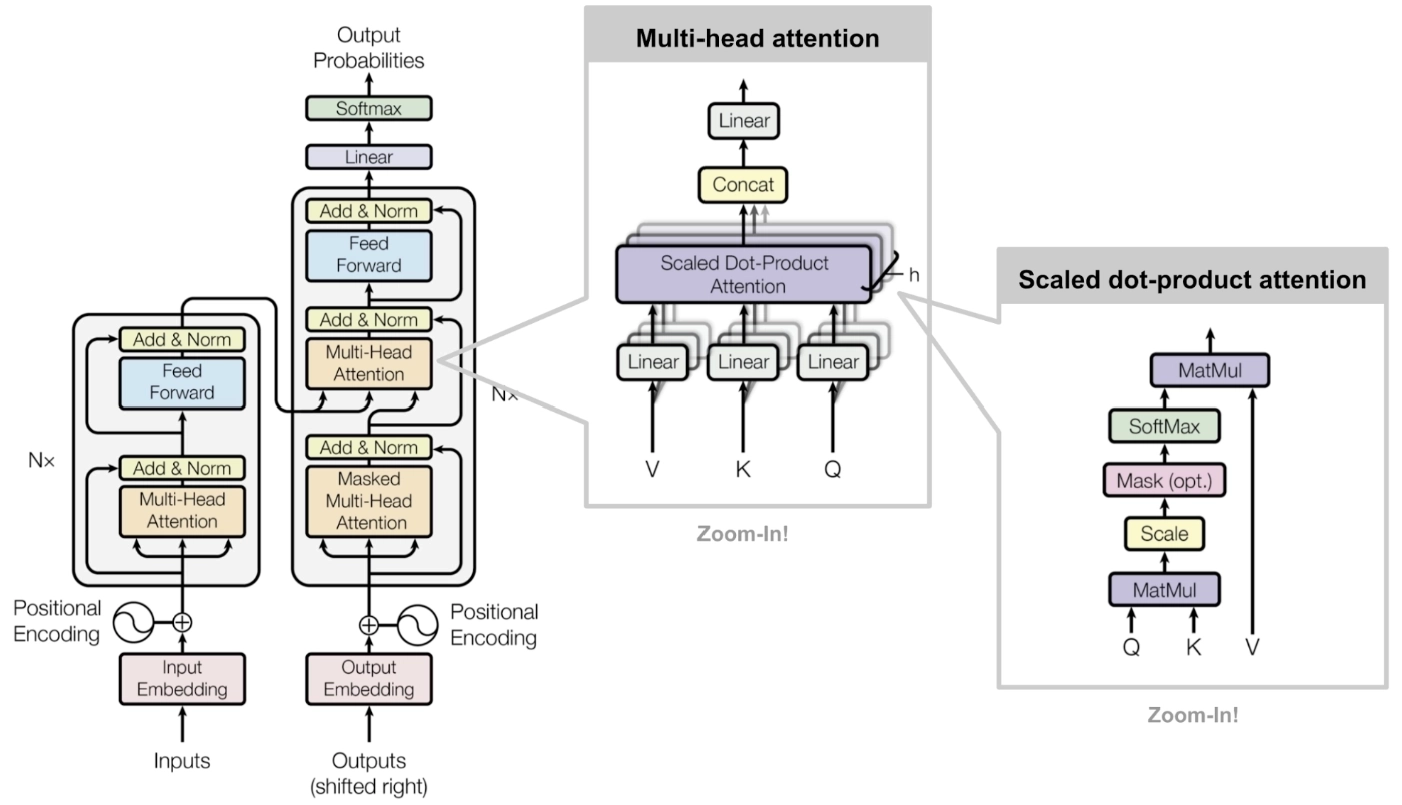

---

### 3-2. Multi-Head Attention 작동 방식

> **핵심** 512차원을 64차원 × 8개 헤드로 나눠 동시에 계산하고, 다시 이어 붙인 뒤 하나로 섞음

"I love you"의 love 한 단어로 보면 (논문처럼 512차원, 헤드 8개, 헤드당 64차원)

| 단계 | 하는 일 | 크기 변화 | 기자 비유 |
| --- | --- | --- | --- |
| ① 분할 (Projection) | 헤드마다 다른 가중치 행렬을 곱해 작은 Q·K·V를 만듦 | 512 → 64 × 8세트 | 기자 8명에게 취재 수첩 배분 |
| ② 병렬 어텐션 계산 | 8개 헤드가 동시에, 서로 간섭 없이 Attention 계산 | 64 × 8개 결과 | 각자 자기 분야 취재 |
| ③ 결합 (Concat) | 8개 결과를 한 줄로 연결 | 64 × 8 → 512 | 기사 8편을 한 묶음으로 |
| ④ 최종 투영 | 마지막 가중치 행렬을 곱해 8개 관점을 하나로 융합 | 512 → 512 | 편집장이 한 기사로 다듬기 |

- **① 분할**: love의 512차원 벡터에 헤드마다 다른 가중치 행렬을 곱해 64차원 Q·K·V를 8세트 만듦. I, you도 똑같이 8세트씩
- **② 병렬 계산** (헤드 1 기준)
  1. 헤드 1에서 만든 love의 Query를 I, love, you의 Key와 각각 내적 → 점수 3개
  2. √64 = 8로 나눔 → 한 단어가 독차지하는 걸 막음
  3. Softmax → EX. I 0.2, love 0.7, you 0.1
  4. 이 비율대로 I, love, you의 Value를 섞으면 헤드 1의 결과(64차원)
  → 헤드 2~8도 각자의 Q·K·V로 동시에, 독립적으로 같은 계산 → 64차원 결과 8개
- **③ Concat**: 8개를 순서대로 이어 붙여 512차원(8 × 64) 하나로
- **④ Final Projection**: 이어 붙인 건 아직 각 헤드 결과를 나열만 한 상태라 마지막 가중치 행렬(512 × 512)을 한 번 더 곱해 **하나의 의미로 융합** → love에 대한 Multi-Head Attention 최종 출력
---

## 4. Transformer 전체 아키텍처

### 4-1. 전처리 단계

> **핵심** 텍스트 입력 → 토큰화 → 임베딩 → Positional Encoding 순서로 문장을 [의미 + 위치] 벡터로 바꿈

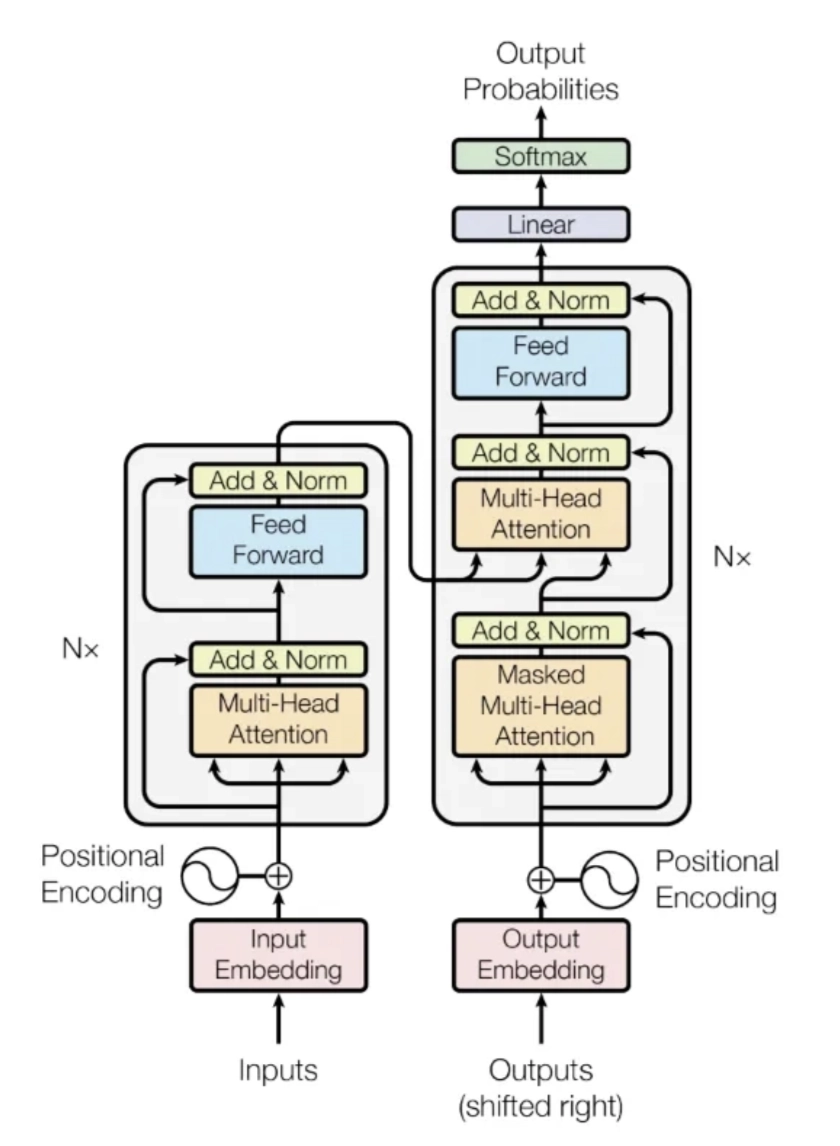

**토큰화 (Tokenization): 문장을 조각내기**
문장을 모델이 다루는 기본 단위(토큰)로 자르는 것. 보통 단어 하나가 토큰 하나(`Give`, `me`, `an`, `apple`)고, 문장 부호도 토큰이며(`.`, `!`), 길거나 드문 단어는 여러 조각으로 나눔(`didn't` → `did` + `n't`). 레고 블록처럼 자주 쓰는 조각을 미리 준비해 두면 처음 보는 단어도 조립해 표현할 수 있음. 논문에선 영→독 번역에 BPE로 약 37,000개, 영→불 번역에 word-piece로 32,000개 토큰 사전을 씀.

**임베딩 (Embedding): 단어에 좌표 주기**
각 토큰을 숫자 벡터로 바꾸는 것. 벡터 길이가 곧 차원(d_model)임 (길이 1,024면 차원도 1,024).
핵심 원리는 **뜻이 비슷한 단어는 가까운 좌표에 놓인다**는 것! 지도로 치면 딸기(5, 4)와 체리(6, 6)는 '과일 동네' 이웃이고 성(2, 1)은 멀리 '건물 동네'에 삶. 실제로는 512차원이라 색깔, 먹을 수 있는지, 크기 등 수백 가지 특징을 동시에 담음. 임베딩 값은 처음엔 무작위인데 학습하면서 의미에 맞는 자리를 찾아가고, 이렇게 단어마다 기본 의미가 담겨 있어야 이후 Attention이 관계를 계산할 수 있음.

참고로 대표적인 임베딩 방법인 **Word2Vec**은 신경망이 다음 단어를 예측하도록 훈련시킨 뒤, 마지막에서 두 번째 레이어의 숫자들을 그 단어의 임베딩으로 씀. 이 층이 단어의 깊은 속성을 담고 있어서, '딸기'와 '사과'처럼 비슷한 다음 단어를 예측하는 단어는 벡터도 비슷해짐.

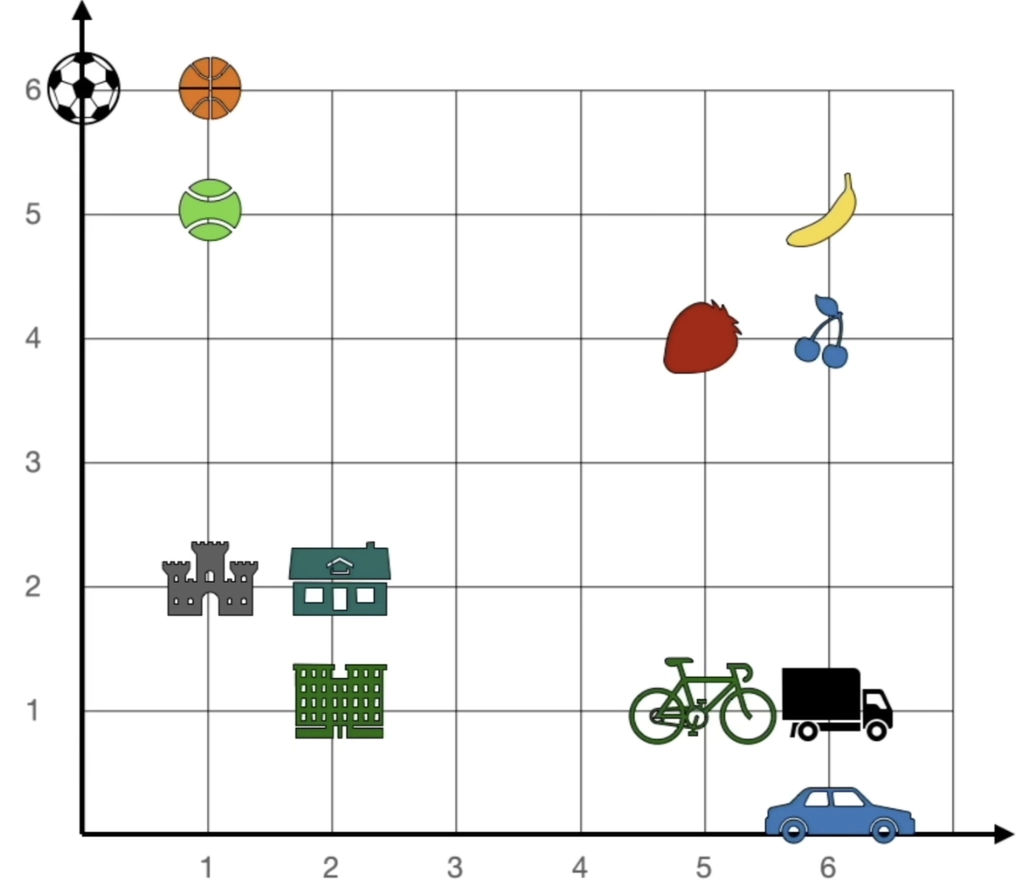

**Positional Encoding: 순서 번호표 붙이기**
Transformer는 모든 단어를 **한꺼번에** 봐서 그냥 두면 순서를 모름 → "개는 고양이를 쫓는다"와 "고양이는 개를 쫓는다"를 같은 단어 묶음으로 봐 버림. RNN은 순서대로 읽어서 자연스럽게 알았지만 Transformer는 따로 알려줘야 함.
그래서 위치마다 정해진 512차원 '위치 벡터'를 만들어 임베딩에 **더함** (이어 붙이는 게 아니라 숫자끼리 더하기). 1번째 자리엔 항상 벡터 A, 2번째엔 항상 벡터 B처럼 **문장이 달라도 규칙이 같아야** 모델이 순서를 배울 수 있고, 같은 단어라도 자리가 다르면 최종 벡터가 달라짐.

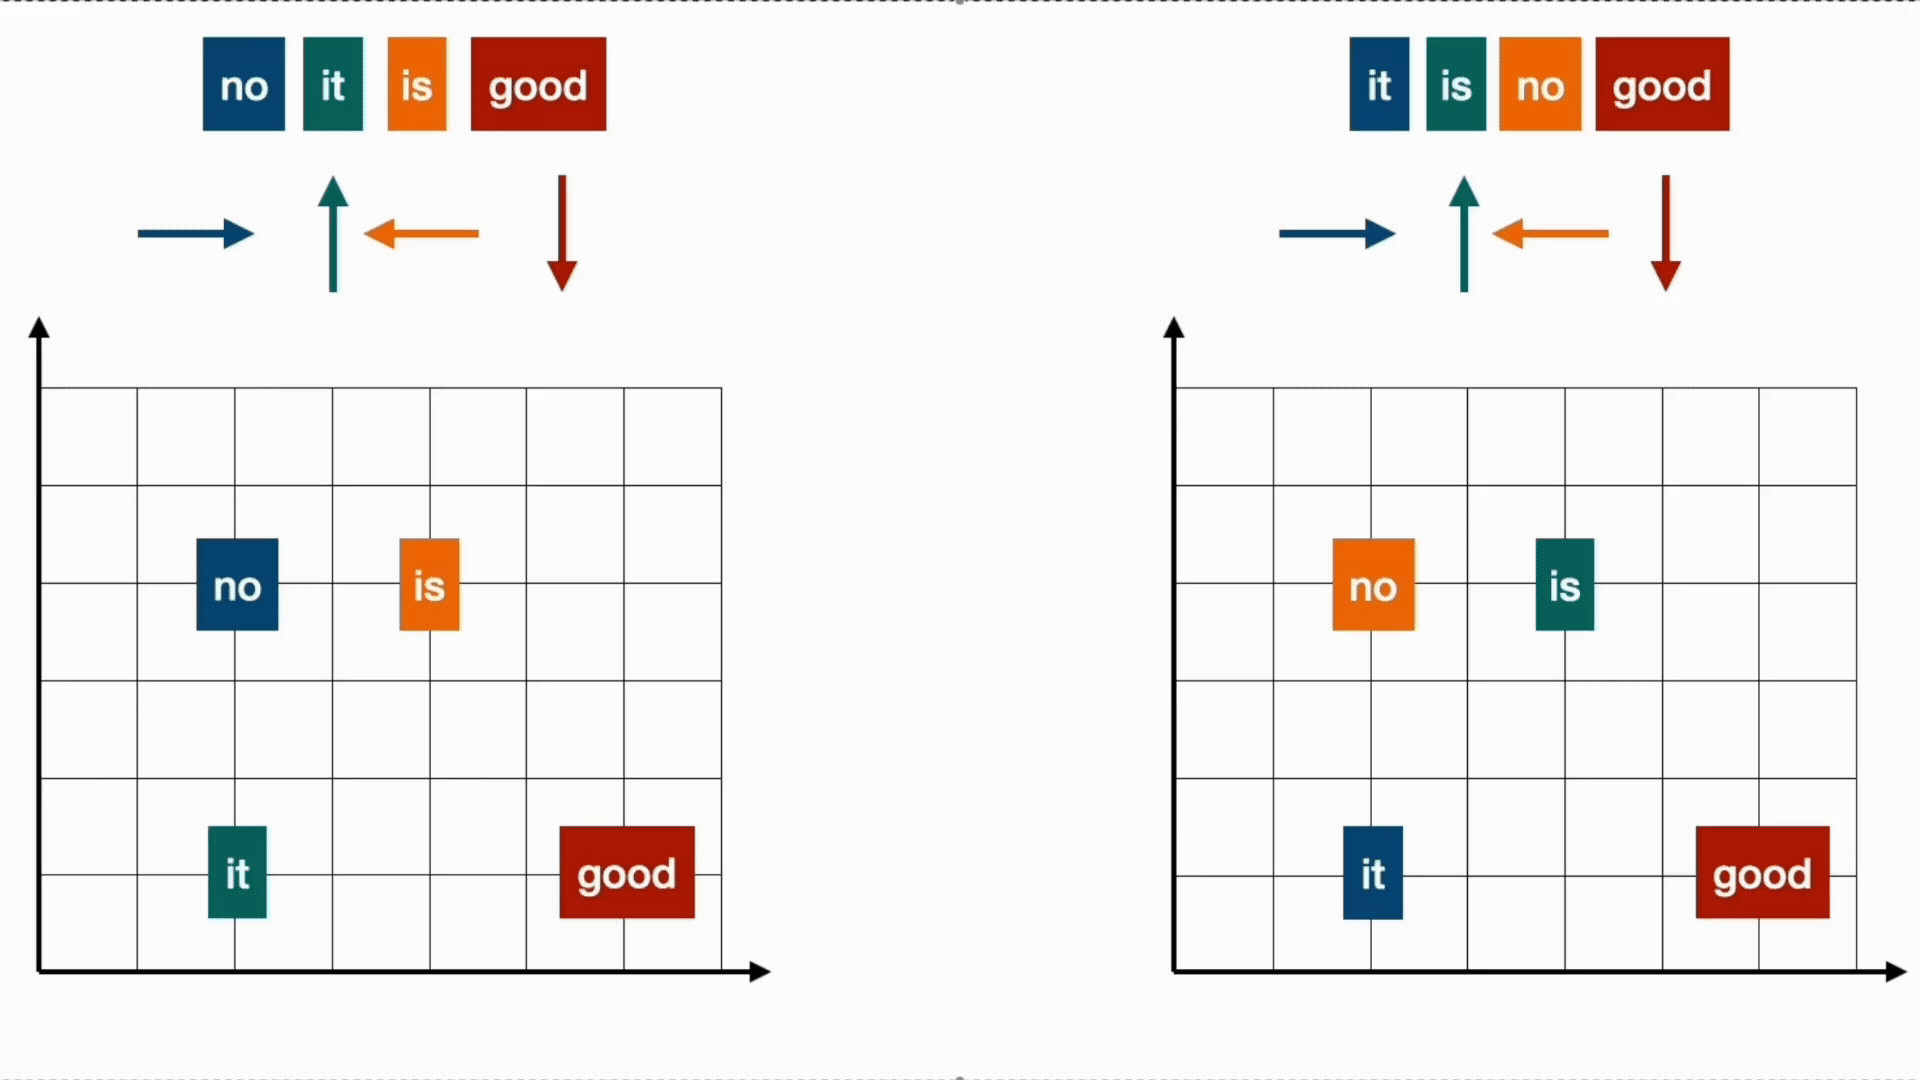

---

### 4-2. Transformer의 Encoder와 Decoder

> **핵심** 인코더는 Self-Attention + FFN으로 원문을 이해하고, 디코더는 Masked Self-Attention + Cross-Attention + FFN으로 한 단어씩 씀. 모든 부품 뒤엔 Add & Norm

**Encoder: 원문을 깊이 이해하는 분석팀**
인코더 층 하나 = 두 부품
1. **Multi-Head Self-Attention**: 원문 단어끼리 서로 보며 문맥 파악
2. **Feed-Forward Network**: 단어 하나하나를 따로 더 깊이 가공

| 구분 | RNN / LSTM Encoder | Transformer Encoder |
| --- | --- | --- |
| 읽는 방식 | 하나씩 순서대로 | 한꺼번에 |
| 정보 전달 | 이전 은닉 상태가 다음 시점으로 | Self-Attention으로 모든 단어가 직접 연결 |
| 순서 정보 | 읽는 순서 자체에 들어 있음 | Positional Encoding으로 따로 넣어 줌 |
| 최종 출력 | 마지막 은닉 상태 하나 | 단어별 문맥 벡터 전부 |

**FFN (Feed-Forward Network)**

$$
\text{FFN}(x) = \max(0,\; xW_1 + b_1)\,W_2 + b_2
$$

512차원을 2048차원으로 **넓혔다가** 다시 512로 **좁히는** 2층 신경망이고 사이에 ReLU가 들어감. **단어마다 따로, 같은 가중치**로 적용돼서 이 단계에선 단어끼리 정보를 안 주고받음.
비유하면 Self-Attention은 학생(단어)들이 서로 의견을 듣는 **조별 토론**, FFN은 토론 끝나고 한 명씩 **같은 선생님**에게 받는 **1:1 첨삭**임. 선생님이 2048개 항목 체크리스트로 노트를 따져보고(512 → 2048), 해당 없는 건 지우고(ReLU), 핵심만 노트 한 장으로 다시 정리해 줌(2048 → 512).

**Add & Norm: 모든 부품에 붙는 안전장치**
- **Add = Residual Connection(잔차 연결)**: 부품을 통과한 결과에 원래 입력을 그대로 더함. CNN의 ResNet에서 나온 아이디어 → 원본은 두고 수정 사항만 덧붙이는 느낌
- **Norm = Layer Normalization**: 한 단어 벡터 안의 512개 숫자를 평균 0, 분산 1 근처로 맞춤 → 발표자마다 다른 마이크 볼륨을 표준 레벨로 맞추듯 학습을 안정적이고 빠르게 함

**Decoder: 번역문을 한 단어씩 쓰는 작성팀**
디코더 층 하나 = 세 부품 (각각 뒤에 Add & Norm), 6층을 다 통과하면 Linear + Softmax로 다음 단어 확률 계산
1. **Masked Multi-Head Self-Attention**: 지금까지 쓴 번역 단어끼리 관계 파악 (미래 단어는 가림)
2. **Encoder-Decoder Attention (Cross-Attention)**: 원문 분석 자료(인코더 출력)에서 필요한 부분 찾기
3. **Feed-Forward Network**: 인코더와 동일

**Masked Multi-Head Attention**
디코더의 Self-Attention에서 미래 시점 단어를 가려서(Softmax 후 0) **자기보다 앞 단어만 보게** 하는 장치. 학습 땐 정답 문장 전체를 한 번에 넣어 병렬로 학습하는데, 마스크가 없으면 답을 미리 보는 "컨닝"이 됨. 시험 볼 때 뒤 문제 답안을 종이로 가려 두는 것과 같음!
EX. "나는 학교에 간다 → I go to school"에서 I go to까지 보고 다음 단어를 예측할 때 school을 미리 보면 학습이 부정확해짐

**Encoder-Decoder Attention (Cross-Attention)**
출력 문장(디코더)과 입력 문장(인코더)을 잇는 과정
- Q = 직전 디코더 서브레이어의 출력
- K·V = 인코더 마지막 층의 출력 (6개 디코더 레이어가 모두 같은 인코더 출력을 씀)
EX. "school"을 만들 차례면 Query는 "I go to"까지의 문맥, Key/Value는 "나는 학교에 간다"를 인코딩한 벡터 → "학교"에 높은 가중치를 줘서 한국어 입력과 영어 출력의 대응을 만듦

---

### 4-3. 전체 모델 및 데이터 흐름

> **핵심** [의미 + 위치] 벡터 → 인코더가 문맥 이해 → 디코더가 원문을 참고하며 한 단어씩 생성, `<end>`가 나오면 종료

"I love you"를 번역하는 흐름으로 정리하면

**입력 준비**
- 임베딩: I, love, you를 각각 의미 벡터로 변환
- Positional Encoding: 0·1·2번 위치 벡터를 더함 → "love"는 "2번째 자리의 love"가 됨

**인코더: 입력 문장의 문맥적 의미 이해**
6개 레이어를 지나면서 레이어마다 아래 순서를 반복함
1. Multi-Head Self-Attention → 단어들이 서로 참조해 문맥을 섞음 ("love"가 주어 "I", 목적어 "you"를 봄)
2. Add & Norm → 입력을 다시 더하고 정규화
3. Feed-Forward (512 → 2048 → 512) → 각 단어 벡터를 따로 가공
4. Add & Norm

→ 출력된 문맥 벡터들이 디코더의 K·V로 전달됨

**디코더: 번역 문장을 한 단어씩 생성**
시작 토큰에서 출발해 Masked Self-Attention(지금까지 만든 단어만) → Cross-Attention(인코더 출력 참조) → FFN을 6층 반복하고, Linear + Softmax로 어휘 전체 확률 중 가장 높은 단어를 출력함

| 단계 | 지금까지의 입력 | ① 내가 쓴 것 보기 (Masked Self-Attention) | ② 원문 보기 (Cross-Attention) | 출력 |
| --- | --- | --- | --- | --- |
| Step 1 | `<start>` | `<start>` 하나뿐 | 첫 단어로 **I**에 집중 | 나는 |
| Step 2 | `<start>` 나는 | 주어까지 썼다는 문맥 파악 | 다음으로 **you**에 집중 | 당신을 |
| Step 3 | `<start>` 나는 당신을 | 주어와 목적어까지 썼다는 문맥 파악 | 남은 **love**에 집중 | 사랑해 |
| Step 4 | `<start>` 나는 당신을 사랑해 | 문장이 완성됐다는 문맥 파악 | 원문에서 더 옮길 내용 없음 | `<end>` → 종료 |

결국! "나는 당신을 사랑해"가 완성됨 